# Feature Scoring — Both Pooling (fac=1, amb=1)

Decision-tree-based feature importance heatmap across all outcomes.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import feature_scoring

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
sub = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
print(f"Policy: Both Pooling (fac=1, amb=1), {len(sub)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
OUTCOMES = [
    "death_rate_T1_BCAS", "death_rate_T2_BCAS", "death_rate_T3_BCAS",
    "median_wait_ccp_transport_T1", "median_wait_ccp_transport_T2",
    "median_wait_r1_care_T1", "median_wait_r1_care_T2",
    "mortality_ccp_transport_T1", "mortality_ccp_transport_T2",
    "mortality_r1_care_T1", "mortality_r1_care_T2",
]

# Filter to outcomes that exist and have variance
OUTCOMES = [o for o in OUTCOMES if o in sub.columns and sub[o].std() > 1e-10]
print(f"Outcomes with variance: {len(OUTCOMES)}")

x = sub[UNCERTAINTIES]
y = sub[OUTCOMES]


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Policy: Both Pooling (fac=1, amb=1), 24576 runs
Outcomes with variance: 7


## Feature Scoring Heatmap


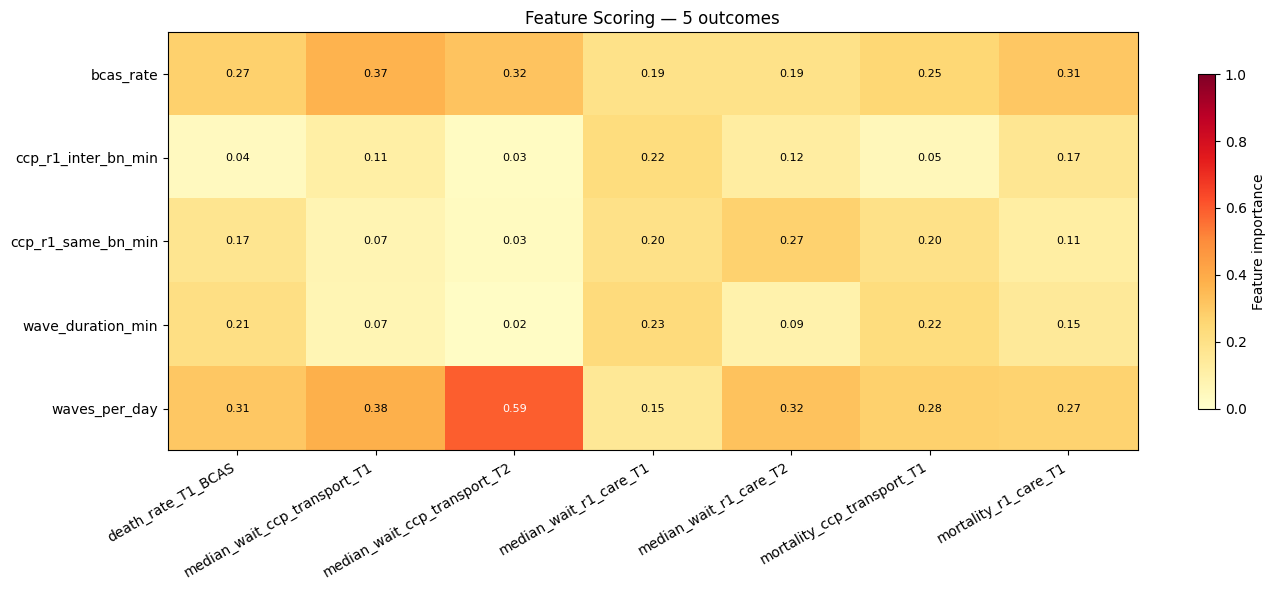

                     death_rate_T1_BCAS  median_wait_ccp_transport_T1  median_wait_ccp_transport_T2  median_wait_r1_care_T1  median_wait_r1_care_T2  mortality_ccp_transport_T1  mortality_r1_care_T1
0                                                                                                                                                                                                    
bcas_rate                         0.274                         0.370                         0.320                   0.192                   0.193                       0.253                 0.307
ccp_r1_inter_bn_min               0.038                         0.112                         0.030                   0.224                   0.124                       0.053                 0.165
ccp_r1_same_bn_min                0.172                         0.072                         0.034                   0.197                   0.270                       0.196                 0.115
wave_durat

In [2]:
scores = feature_scoring.get_feature_scores_all(x, y)
scored_outcomes = scores.index.tolist()
scored_uncertainties = scores.columns.tolist()

fig, ax = plt.subplots(figsize=(14, max(6, len(scored_outcomes) * 0.5)))
im = ax.imshow(scores.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(scored_uncertainties)))
ax.set_xticklabels(scored_uncertainties, rotation=30, ha="right")
ax.set_yticks(range(len(scored_outcomes)))
ax.set_yticklabels(scored_outcomes)
ax.set_title(f"Feature Scoring — {len(scored_outcomes)} outcomes")

for i in range(len(scored_outcomes)):
    for j in range(len(scored_uncertainties)):
        v = scores.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.5 else "black")

plt.colorbar(im, ax=ax, shrink=0.8, label="Feature importance")
plt.tight_layout()
plt.show()

print(scores.to_string(float_format="%.3f"))


## Ranked Features per Outcome


In [3]:
for outcome in scores.index:
    ranked = scores.loc[outcome].sort_values(ascending=False)
    print(f"
{outcome}:")
    for feat, score in ranked.items():
        bar = "█" * int(score * 20)
        print(f"  {feat:<25} {score:.3f} {bar}")


KeyError: 'death_rate_T1_BCAS'